# Universidad Autonoma de Aguascalientes
# Departamento: Ciencias de la Computacion
# Carrera: Ingenieria en Computacion Inteligente
## Curso: Lenguajes Inteligentes
## Maestro: Dr.Francisco Javier Lunas Rosas
## Alumno: Luis Fernando Silva Briones
### Semestre: Agosto_Diciembre del 2026

## Practica #6: Filtros RGB, escala de grises e histogramas.

### Los filtros de colores de una imagen son técnicas de procesamiento digital que permiten modificar, seleccionar o resaltar determinados colores de una imagen para mejorar su apariencia o facilitar su análisis. En esta practica diseñaremos un programa en python que implemente filtros de colores y nos muestre los histogramas de la misma imagen con diferente filtro.


### Paso 1. Importar las librerías

In [2]:
from PIL import Image, ImageOps
import numpy as np
import matplotlib.pyplot as plt
from tkinter import Tk, filedialog

### Paso 2. Cargar la imagen

Imagen cargada correctamente: C:/Users/silva/Downloads/3.jpg


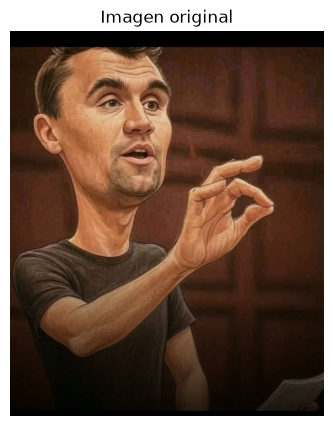

In [3]:
# Cargamos la imagen escribiendo su ruta directamente en el codigo
# Cambia esta ruta por la ubicacion de tu imagen
ruta_imagen = "C:/Users/silva/Downloads/3.jpg"

imagen_original = Image.open(ruta_imagen).convert("RGB")
print("Imagen cargada correctamente:", ruta_imagen)

plt.figure(figsize=(7, 5))
plt.imshow(imagen_original)
plt.title("Imagen original")
plt.axis("off")
plt.show()

### Paso 3. Crear los filtros con Pillow

In [4]:
# Cada filtro conserva un canal de color y pone los otros dos en cero.
arreglo = np.array(imagen_original)

canal_rojo = np.zeros_like(arreglo)
canal_rojo[:, :, 0] = arreglo[:, :, 0]
imagen_roja = Image.fromarray(canal_rojo)

canal_verde = np.zeros_like(arreglo)
canal_verde[:, :, 1] = arreglo[:, :, 1]
imagen_verde = Image.fromarray(canal_verde)

canal_azul = np.zeros_like(arreglo)
canal_azul[:, :, 2] = arreglo[:, :, 2]
imagen_azul = Image.fromarray(canal_azul)

imagen_grises = ImageOps.grayscale(imagen_original)

print("Se generaron los filtros rojo, verde, azul y escala de grises.")

Se generaron los filtros rojo, verde, azul y escala de grises.


### Paso 4. Función para mostrar la imagen y su histograma

In [5]:
def mostrar_imagen_histograma(imagen, titulo, modo="RGB"):
    # Convertir la imagen a RGB o a escala de grises para obtener sus datos
    if modo == "L":
        imagen_datos = imagen.convert("L")
        valores = np.array(imagen_datos)
        histograma = np.histogram(valores, bins=256, range=(0, 256))[0]
        maximo = histograma.max()
        histograma_normalizado = histograma / maximo if maximo > 0 else histograma

        fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))
        ejes[0].imshow(imagen_datos, cmap="gray", vmin=0, vmax=255)
        ejes[0].set_title(titulo)
        ejes[0].axis("off")

        ejes[1].plot(range(256), histograma_normalizado, color="black")
        ejes[1].set_title("Histograma de grises normalizado")
        ejes[1].set_xlabel("Intensidad (0 a 255)")
        ejes[1].set_ylabel("Frecuencia normalizada (0 a 1)")
        ejes[1].set_xlim(0, 255)
        ejes[1].set_ylim(0, 1.05)
        ejes[1].grid(True, alpha=0.3)
    else:
        imagen_datos = imagen.convert("RGB")
        arreglo = np.array(imagen_datos)
        colores = ["red", "green", "blue"]
        nombres = ["Rojo", "Verde", "Azul"]

        fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))
        ejes[0].imshow(imagen_datos)
        ejes[0].set_title(titulo)
        ejes[0].axis("off")

        for i in range(3):
            histograma = np.histogram(arreglo[:, :, i], bins=256, range=(0, 256))[0]
            maximo = histograma.max()
            histograma_normalizado = histograma / maximo if maximo > 0 else histograma
            ejes[1].plot(range(256), histograma_normalizado,
                         color=colores[i], label=nombres[i])

        ejes[1].set_title("Histograma RGB normalizado")
        ejes[1].set_xlabel("Intensidad (0 a 255)")
        ejes[1].set_ylabel("Frecuencia normalizada (0 a 1)")
        ejes[1].set_xlim(0, 255)
        ejes[1].set_ylim(0, 1.05)
        ejes[1].legend()
        ejes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

### Paso 5. Imagen original e histograma RGB

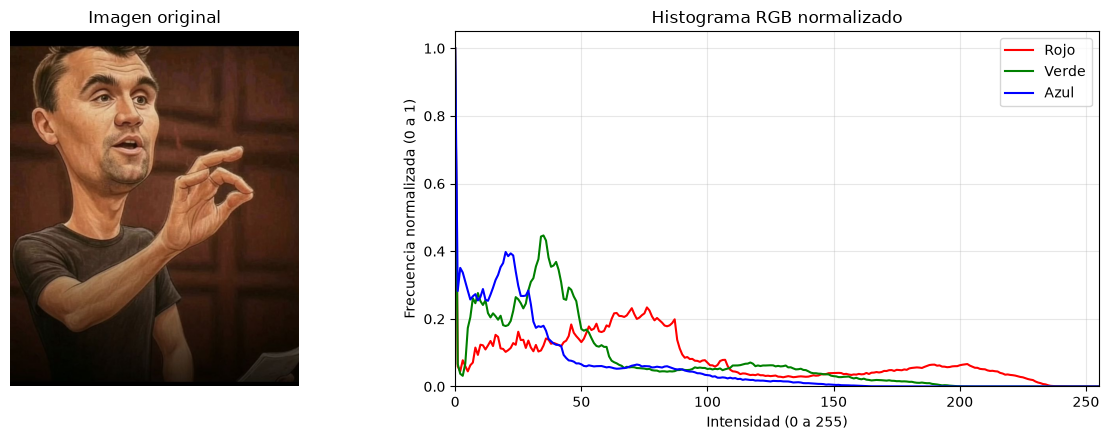

In [6]:
mostrar_imagen_histograma(imagen_original, "Imagen original", modo="RGB")

### Paso 6. Filtro rojo e histograma

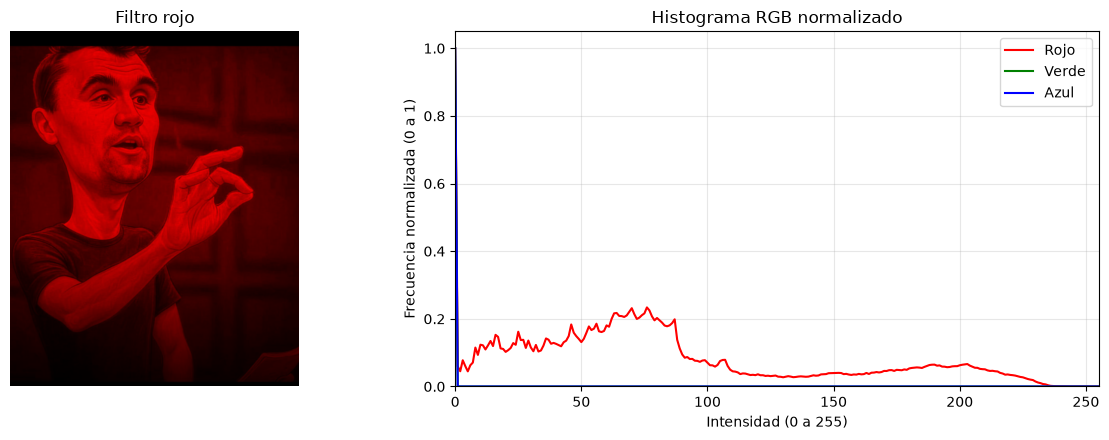

In [7]:
mostrar_imagen_histograma(imagen_roja, "Filtro rojo", modo="RGB")

### Paso 7. Filtro verde e histograma

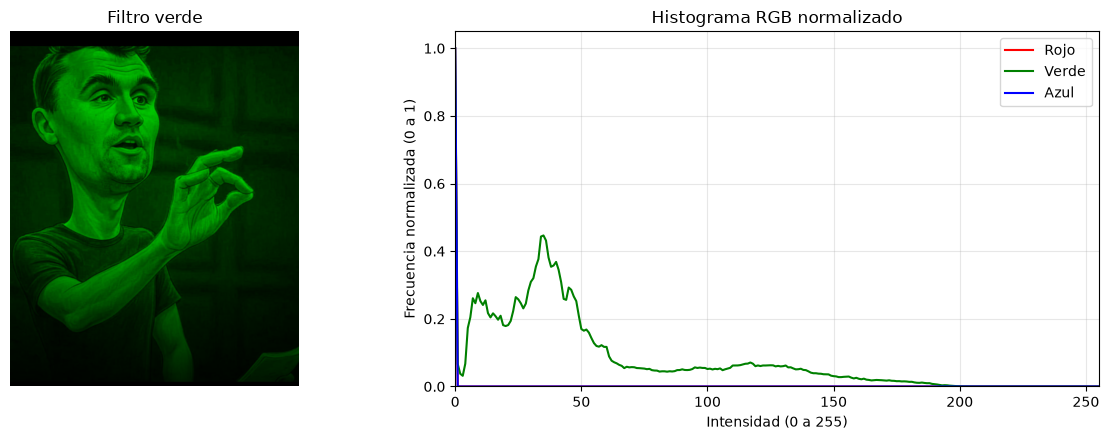

In [8]:
mostrar_imagen_histograma(imagen_verde, "Filtro verde", modo="RGB")

### Paso 8. Filtro azul e histograma

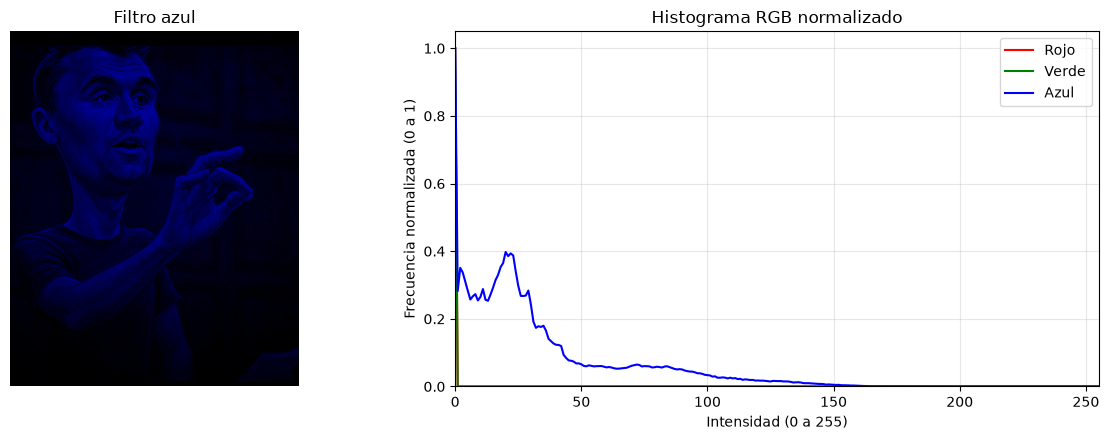

In [9]:
mostrar_imagen_histograma(imagen_azul, "Filtro azul", modo="RGB")

### Paso 9. Escala de grises e histograma

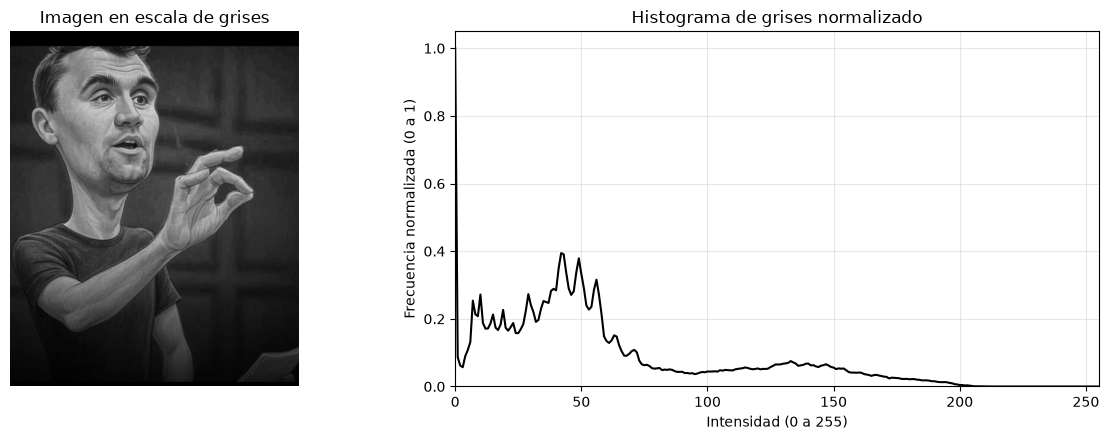

In [10]:
mostrar_imagen_histograma(imagen_grises, "Imagen en escala de grises", modo="L")

## Conclusión

Pillow permite abrir, transformar y convertir imágenes de manera sencilla. Al observar los histogramas RGB y de escala de grises se puede apreciar cómo se distribuyen las intensidades de los píxeles. El eje horizontal conserva los niveles de 0 a 255 y el eje vertical se normaliza entre 0 y 1 para facilitar la comparación visual.

## Referencias

### URL: Imagenes en Python, (Pillow 2026)
https://pillow.readthedocs.io/en/stable/ (Ultimo acceso Octubre de 2026).